# DBpedia EDA - entities with coordinates

## Imports and settings

In [8]:
from collections import Counter
from glob import glob
import os

import numpy as np
import pandas as pd
import geopandas as gpd
import geoplot as gplt
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LogNorm
from shapely.geometry import box
from IPython.display import Image, display

DBPEDIA_DIR = "../data/dbpedia"

## Filter entities with both latitude and longitude

In [ ]:
coordinate_predicates = {
    b"<http://www.w3.org/2003/01/geo/wgs84_pos#lat>": "latitude",
    b"<http://www.w3.org/2003/01/geo/wgs84_pos#long>": "longitude",
}
entity_coordinates = {}
with open(f"{DBPEDIA_DIR}/geo_coordinates_mappingbased_en.ttl", "rb") as stream:
    for line in stream:
        if not line.startswith(b"<"):
            continue
        subject, predicate, obj = line.split(None, 2)
        if predicate in coordinate_predicates:
            entity = subject[1:-1].decode("utf-8")
            row = entity_coordinates.setdefault(entity, {"entity": entity})
            # One coordinate pair per entity, using the first stored values.
            row.setdefault(coordinate_predicates[predicate], float(obj.split(b'"', 2)[1]))

coordinates = pd.DataFrame.from_records(list(entity_coordinates.values())).dropna(
    subset=["latitude", "longitude"]
).reset_index(drop=True)
del entity_coordinates
located_subjects = {f"<{entity}>".encode("utf-8") for entity in coordinates["entity"]}
print(f"Entities retained: {len(coordinates):,}")
display(coordinates.head(20))

Entities retained: 584,587


,entity,latitude,longitude
0,http://dbpedia.org/resource/Algeria,36.700000,3.216667
1,http://dbpedia.org/resource/Andorra,42.500000,1.516667
2,http://dbpedia.org/resource/Aruba,12.516667,-70.033333
3,http://dbpedia.org/resource/Angola,-8.833333,13.333333
4,http://dbpedia.org/resource/Albania,41.333333,19.800000
5,http://dbpedia.org/resource/Afghanistan,34.533333,69.133333
6,http://dbpedia.org/resource/Azerbaijan,40.416667,49.833333
7,http://dbpedia.org/resource/Ankara,39.933333,32.866667
8,http://dbpedia.org/resource/Aegean_Sea,39.000000,25.000000
9,http://dbpedia.org/resource/Alfred_Nobel__rest...,59.356811,18.019286


## Source file sizes

In [ ]:
dbpedia_files = sorted(glob(f"{DBPEDIA_DIR}/*.ttl"))
inventory = pd.DataFrame([
    {"file": os.path.basename(path), "size_GB": os.path.getsize(path) / 1e9}
    for path in dbpedia_files
]).sort_values("size_GB", ascending=False).reset_index(drop=True)
display(inventory)
print(f"Total source files: {inventory['size_GB'].sum():.2f} GB")

Total source files: 12.61 GB


,file,size_GB
0,instance_types_transitive_en.ttl,4.565067
1,article_categories_en.ttl,3.452334
2,mappingbased_objects_en.ttl,2.516973
3,skos_categories_en.ttl,0.972973
4,instance_types_en.ttl,0.756373
5,geo_coordinates_mappingbased_en.ttl,0.346856


## Filtered dataset counts and attributes

In [ ]:
predicate_counts = Counter()
literal_counts = Counter()
first_examples = {}
type_ids = {}
entity_type_masks = dict.fromkeys(located_subjects, 0)
type_predicate = b"<http://www.w3.org/1999/02/22-rdf-syntax-ns#type>"
filtered_file_counts = []

# Filter subjects; keep their outgoing facts, including references to other entities.
for path in dbpedia_files:
    statement_count = 0
    with open(path, "rb") as stream:
        for line in stream:
            if not line.startswith(b"<"):
                continue
            subject, predicate, obj = line.split(None, 2)
            if subject not in located_subjects:
                continue
            predicate_counts[predicate] += 1
            statement_count += 1
            first_examples.setdefault(predicate, obj.rstrip()[:-1].rstrip())
            if obj.startswith(b'"'):
                literal_counts[predicate] += 1
            if predicate == type_predicate:
                type_uri = obj[1:obj.index(b">")]
                if type_uri not in type_ids:
                    type_ids[type_uri] = len(type_ids)
                entity_type_masks[subject] |= 1 << type_ids[type_uri]
    filename = os.path.basename(path)
    filtered_file_counts.append({"file": filename, "statements": statement_count})

located_attributes = pd.DataFrame([
    {
        "predicate": predicate[1:-1].decode("utf-8"),
        "statements": count,
        "resource_statements": count - literal_counts[predicate],
        "literal_statements": literal_counts[predicate],
        "example_object": first_examples[predicate].decode("utf-8"),
    }
    for predicate, count in sorted(predicate_counts.items())
])

# Bit masks count each entity only once per type, including across source files.
type_node_counts = Counter()
for mask in entity_type_masks.values():
    while mask:
        bit = mask & -mask
        type_node_counts[bit.bit_length() - 1] += 1
        mask ^= bit
type_counts = pd.DataFrame([
    {"type": uri.decode("utf-8"), "node_count": type_node_counts[type_id]}
    for uri, type_id in type_ids.items()
])
# Classify the entity itself, rather than objects linked through country/location.
# Settlement includes cities, towns, villages, and other settlement subclasses.
administrative_type_names = ["Country", "Settlement", "AdministrativeRegion"]
administrative_mask = 0
for name in administrative_type_names:
    type_id = type_ids.get(f"http://dbpedia.org/ontology/{name}".encode("utf-8"))
    if type_id is not None:
        administrative_mask |= 1 << type_id
clerical_type_id = type_ids.get(b"http://dbpedia.org/ontology/ClericalAdministrativeRegion")
clerical_mask = 0 if clerical_type_id is None else 1 << clerical_type_id
administrative_subjects = {
    subject for subject, mask in entity_type_masks.items()
    if mask & administrative_mask and not mask & clerical_mask
}
administrative_breakdown_names = [
    "Country", "City", "Town", "Village", "Settlement", "AdministrativeRegion",
]
administrative_rows = []
for name in administrative_breakdown_names:
    type_id = type_ids.get(f"http://dbpedia.org/ontology/{name}".encode("utf-8"))
    bit = 0 if type_id is None else 1 << type_id
    administrative_rows.append({
        "type": f"dbo:{name}",
        "entities": sum(bool(entity_type_masks[subject] & bit) for subject in administrative_subjects),
    })
administrative_counts = pd.DataFrame(administrative_rows)

del entity_type_masks
statistics = {
    "entities_with_coordinates": len(coordinates),
    "statements": int(located_attributes["statements"].sum()),
    "distinct_predicates": len(located_attributes),
    "distinct_types": len(type_counts),
    "literal_statements": int(located_attributes["literal_statements"].sum()),
}
display(pd.DataFrame.from_dict(statistics, orient="index", columns=["count"]))
with pd.option_context("display.max_rows", 20, "display.max_colwidth", None):
    display(located_attributes[["predicate", "statements", "resource_statements", "literal_statements"]])

,count
entities_with_coordinates,584587
statements,10900280
distinct_predicates,235
distinct_types,157
literal_statements,1755094


,predicate,statements,resource_statements,literal_statements
0,http://dbpedia.org/ontology/actScore,8,8,0
1,http://dbpedia.org/ontology/addressInRoad,9,9,0
2,http://dbpedia.org/ontology/administrativeCollectivity,245,245,0
3,http://dbpedia.org/ontology/administrativeDistrict,200,200,0
4,http://dbpedia.org/ontology/administrator,1,1,0
...,...,...,...,...
230,http://www.w3.org/2003/01/geo/wgs84_pos#long,585023,0,585023
231,http://xmlns.com/foaf/0.1/depiction,2462,2462,0
232,http://xmlns.com/foaf/0.1/homepage,100013,100013,0
233,http://xmlns.com/foaf/0.1/logo,13,13,0


## Top 20 attributes of entities with both latitude and longitude

Ranked by outgoing statement count within this group. The percentage is the share of all statements from these entities.

In [ ]:
print(f"Top 20 most frequent attributes among {len(coordinates):,} entities with both latitude and longitude")
top_attributes = located_attributes.nlargest(20, "statements").copy()
top_attributes["attribute"] = top_attributes["predicate"].str.replace(
    "http://dbpedia.org/ontology/", "dbo:", regex=False
).str.replace("http://www.w3.org/1999/02/22-rdf-syntax-ns#", "rdf:", regex=False).str.replace(
    "http://purl.org/dc/terms/", "dcterms:", regex=False
).str.replace("http://www.w3.org/2004/02/skos/core#", "skos:", regex=False).str.replace(
    "http://www.w3.org/2003/01/geo/wgs84_pos#", "geo:", regex=False
).str.replace("http://www.georss.org/georss/", "georss:", regex=False)
top_attributes["share_percent"] = (100 * top_attributes["statements"] / located_attributes["statements"].sum()).round(2)
display(top_attributes[["attribute", "statements", "share_percent"]].reset_index(drop=True))

Top 20 most frequent attributes among 584,587 entities with both latitude and longitude


,attribute,statements,share_percent
0,rdf:type,5222175,47.91
1,dcterms:subject,1448370,13.29
2,dbo:isPartOf,700815,6.43
3,georss:point,585052,5.37
4,geo:long,585023,5.37
5,geo:lat,585019,5.37
6,dbo:country,431134,3.96
7,dbo:timeZone,284118,2.61
8,dbo:type,185340,1.70
9,dbo:location,163078,1.50


## Top 20 types of located entities

In [ ]:
print("Top 20 types among entities with both latitude and longitude - distinct nodes")
top_types = type_counts.nlargest(20, "node_count").copy()
top_types["type"] = top_types["type"].str.replace(
    "http://dbpedia.org/ontology/", "dbo:", regex=False
).str.replace("http://www.w3.org/2002/07/owl#", "owl:", regex=False).str.replace(
    "http://schema.org/", "schema:", regex=False
).str.replace("http://www.w3.org/2004/02/skos/core#", "skos:", regex=False).str.replace(
    "http://www.w3.org/2003/01/geo/wgs84_pos#", "geo:", regex=False
)
display(top_types.reset_index(drop=True))

Top 20 types among entities with both latitude and longitude - distinct nodes


,type,node_count
0,geo:SpatialThing,584587
1,owl:Thing,567814
2,dbo:Place,534454
3,schema:Place,534454
4,dbo:Location,534454
5,dbo:PopulatedPlace,391751
6,http://www.wikidata.org/entity/Q486972,391751
7,dbo:Settlement,378026
8,dbo:Village,122339
9,http://www.wikidata.org/entity/Q532,122339


## Administrative areas, settlements, human-made structures, and organizations

All rows count distinct entities with both latitude and longitude. Administrative and settlement rows cover countries, cities, towns, villages, other settlements, and administrative regions; explicitly typed ecclesiastical regions are excluded from those rows. Human-made structures and organizations are counted across the full coordinate-filtered group.

Rows overlap: a city can also be a settlement, and a building can also be an architectural structure. The printed subtotal covers only administrative and settlement entities, counting each once; it does not include the added structure and organization rows. DBpedia classifications can include historical entities.


In [ ]:
administrative_total = len(administrative_subjects)
administrative_share = 100 * administrative_total / len(coordinates) if len(coordinates) else 0
print(f"Administrative and settlement subtotal (distinct entities): {administrative_total:,}")
print(f"Share of entities with both coordinates: {administrative_share:.2f}%")
# Count these additional types across all entities with both coordinates.
human_made_type_names = ["ArchitecturalStructure", "Building", "Infrastructure", "Organisation"]
human_made_type_uris = [f"http://dbpedia.org/ontology/{name}" for name in human_made_type_names]
human_made_counts = type_counts.loc[
    type_counts["type"].isin(human_made_type_uris), ["type", "node_count"]
].copy()
human_made_counts["type"] = human_made_counts["type"].str.replace(
    "http://dbpedia.org/ontology/", "dbo:", regex=False
)
human_made_counts = human_made_counts.rename(columns={"node_count": "entities"}).sort_values(
    ["entities", "type"], ascending=[False, True]
)
human_related_counts = pd.concat([administrative_counts, human_made_counts], ignore_index=True)
print("Administrative areas, settlements, human-made structures, and organizations")
display(human_related_counts)



Administrative and settlement subtotal (distinct entities): 387,090
Share of entities with both coordinates: 66.22%
Administrative areas, settlements, human-made structures, and organizations


,type,entities
0,dbo:Country,543
1,dbo:City,18802
2,dbo:Town,34574
3,dbo:Village,122339
4,dbo:Settlement,378026
5,dbo:AdministrativeRegion,8521
6,dbo:ArchitecturalStructure,94478
7,dbo:Building,49389
8,dbo:Infrastructure,39178
9,dbo:Organisation,33333


## Natural features with both latitude and longitude

Distinct entities per natural-feature type, using the same coordinate-filtered type counts. Rows overlap: a lake can also be a body of water and a natural place. Types with no matching entities are omitted.


In [ ]:
natural_type_names = [
    "NaturalPlace", "Mountain", "MountainRange", "Volcano", "MountainPass",
    "BodyOfWater", "Lake", "River", "Stream", "Sea", "Bay",
    "Island", "Glacier", "Cave", "Valley", "Crater",
]
natural_type_uris = [f"http://dbpedia.org/ontology/{name}" for name in natural_type_names]
natural_counts = type_counts.loc[
    type_counts["type"].isin(natural_type_uris), ["type", "node_count"]
].copy()
natural_counts["type"] = natural_counts["type"].str.replace(
    "http://dbpedia.org/ontology/", "dbo:", regex=False
)
natural_counts = natural_counts.rename(columns={"node_count": "entities"}).sort_values(
    ["entities", "type"], ascending=[False, True]
).reset_index(drop=True)
print("Natural features among entities with both latitude and longitude")
display(natural_counts)


Natural features among entities with both latitude and longitude


,type,entities
0,dbo:NaturalPlace,25135
1,dbo:Mountain,13753
2,dbo:BodyOfWater,10535
3,dbo:Lake,9547
4,dbo:Island,4661
5,dbo:Volcano,765
6,dbo:Valley,79
7,dbo:Sea,32
8,dbo:River,22
9,dbo:Stream,22


## Top 20 categories by coordinate-filtered member entities

Rank categories by the number of distinct entities with both latitude and longitude directly assigned through `dcterms:subject`. Membership is not expanded through the category hierarchy. `direct_subcategories` separately counts immediate child categories from `skos:broader` in the full category graph; these category nodes do not need coordinates. The two counts describe different kinds of children.


In [ ]:
# Reuse the same set of entities with both latitude and longitude.
subject_ids = {subject: index for index, subject in enumerate(located_subjects)}
category_members = {}
category_predicate = b"<http://purl.org/dc/terms/subject>"
category_prefix = b"http://dbpedia.org/resource/Category:"
with open(f"{DBPEDIA_DIR}/article_categories_en.ttl", "rb") as stream:
    for line in stream:
        if not line.startswith(b"<"):
            continue
        subject, predicate, obj = line.split(None, 2)
        if predicate != category_predicate or subject not in subject_ids or not obj.startswith(b"<"):
            continue
        category_uri = obj[1:obj.index(b">")]
        if category_uri.startswith(category_prefix):
            category_members.setdefault(category_uri, set()).add(subject_ids[subject])

category_counts = pd.DataFrame(
    [{"category_uri": uri.decode("utf-8"), "member_entities": len(members)}
     for uri, members in category_members.items()],
    columns=["category_uri", "member_entities"],
).sort_values(["member_entities", "category_uri"], ascending=[False, True])
top_categories = category_counts.head(20).copy()
del category_members, subject_ids

# A skos:broader statement points from a child category to its parent.
category_children = {uri.encode("utf-8"): set() for uri in top_categories["category_uri"]}
broader_predicate = b"<http://www.w3.org/2004/02/skos/core#broader>"
with open(f"{DBPEDIA_DIR}/skos_categories_en.ttl", "rb") as stream:
    for line in stream:
        if not line.startswith(b"<"):
            continue
        child, predicate, obj = line.split(None, 2)
        if predicate != broader_predicate or not obj.startswith(b"<"):
            continue
        parent_uri = obj[1:obj.index(b">")]
        if parent_uri in category_children and child[1:-1].startswith(category_prefix):
            category_children[parent_uri].add(child)
top_categories["direct_subcategories"] = [
    len(category_children[uri.encode("utf-8")]) for uri in top_categories["category_uri"]
]
top_categories["category"] = top_categories["category_uri"].str.replace(
    "http://dbpedia.org/resource/", "", regex=False
)
print("Top 20 categories by distinct member entities with both coordinates")
with pd.option_context("display.max_colwidth", None):
    display(top_categories[["category", "member_entities", "direct_subcategories"]].reset_index(drop=True))
del category_children


Top 20 categories by distinct member entities with both coordinates


,category,member_entities,direct_subcategories
0,Category:Villages_in_the_Czech_Republic,4093,2
1,Category:Unincorporated_communities_in_West_Virginia,2863,1
2,Category:Mountains_of_the_Alps,2555,10
3,Category:Unincorporated_communities_in_California,1905,7
4,Category:Houses_on_the_National_Register_of_Historic_Places_in_New_York,1842,1
5,Category:Townships_in_Minnesota,1774,3
6,Category:Villages_in_Turkey,1673,0
7,Category:Unincorporated_communities_in_Kentucky,1642,1
8,Category:Mountains_of_Switzerland,1476,5
9,Category:Unincorporated_communities_in_Wisconsin,1439,2


## Geographic distance between linked entities

Great-circle distances in kilometres for unique unordered pairs linked in `mappingbased_objects_en.ttl`, requiring both latitude and longitude at both endpoints. Repeated links, different predicates between the same endpoints, and reciprocal links count as one pair. Self-links are excluded; distinct entities at identical coordinates retain their zero distance. Distances use the stored representative coordinate of each entity, including countries and regions, rather than travel distances or boundary-to-boundary distances.


In [ ]:
# Index the coordinate-filtered entities for bounded, vectorized distance batches.
distance_coordinates = coordinates.dropna(subset=["latitude", "longitude"]).reset_index(drop=True)
if not len(distance_coordinates):
    raise ValueError("No entities have both latitude and longitude.")
lat_lon = distance_coordinates[["latitude", "longitude"]].to_numpy(dtype=float)
if not (np.isfinite(lat_lon).all() and (np.abs(lat_lon[:, 0]) <= 90).all()
        and (np.abs(lat_lon[:, 1]) <= 180).all()):
    raise ValueError("Coordinates must be finite and within valid latitude/longitude bounds.")
coordinate_ids = {
    f"<{entity}>".encode("utf-8"): index
    for index, entity in enumerate(distance_coordinates["entity"])
}
lat_lon_radians = np.radians(lat_lon)
earth_radius_km = 6371.0088
seen_pairs = set()
left_ids, right_ids, distance_chunks = [], [], []

def calculate_distance_batch():
    first = lat_lon_radians[np.asarray(left_ids)]
    second = lat_lon_radians[np.asarray(right_ids)]
    delta = second - first
    haversine = (np.sin(delta[:, 0] / 2) ** 2
                 + np.cos(first[:, 0]) * np.cos(second[:, 0]) * np.sin(delta[:, 1] / 2) ** 2)
    distance_chunks.append(2 * earth_radius_km * np.arcsin(np.sqrt(np.clip(haversine, 0, 1))))
    left_ids.clear()
    right_ids.clear()

with open(f"{DBPEDIA_DIR}/mappingbased_objects_en.ttl", "rb") as stream:
    for line in stream:
        if not line.startswith(b"<"):
            continue
        subject, predicate, obj = line.split(None, 2)
        source_id = coordinate_ids.get(subject)
        if source_id is None or not obj.startswith(b"<"):
            continue
        target_id = coordinate_ids.get(obj[:obj.index(b">") + 1])
        if target_id is None or source_id == target_id:
            continue
        first_id, second_id = sorted((source_id, target_id))
        pair_id = first_id * len(distance_coordinates) + second_id
        if pair_id in seen_pairs:
            continue
        seen_pairs.add(pair_id)
        left_ids.append(first_id)
        right_ids.append(second_id)
        if len(left_ids) >= 100_000:
            calculate_distance_batch()
if left_ids:
    calculate_distance_batch()
linked_distances_km = np.concatenate(distance_chunks) if distance_chunks else np.array([], dtype=float)
del seen_pairs, coordinate_ids, distance_chunks, left_ids, right_ids


### Distance distribution and descriptive statistics

Run the preceding distance calculation first. The table reports the minimum, quartiles, median, maximum, mean, and population standard deviation in kilometres. Two vertically stacked histograms use identical bins and a shared linear distance axis: sample counts are linear on top and logarithmic on the bottom. Zero-distance pairs are included. Metric lines and annotations are omitted from the charts.


Geographic distances for 1,005,722 unique linked entity pairs


,statistic,distance_km
0,Minimum,0.00
1,"First quartile (Q1, 25%)",12.25
2,"Median (Q2, 50%)",74.09
3,"Third quartile (Q3, 75%)",328.27
4,Maximum,19981.67
5,Average (mean),428.54
6,Standard deviation (population),1202.30


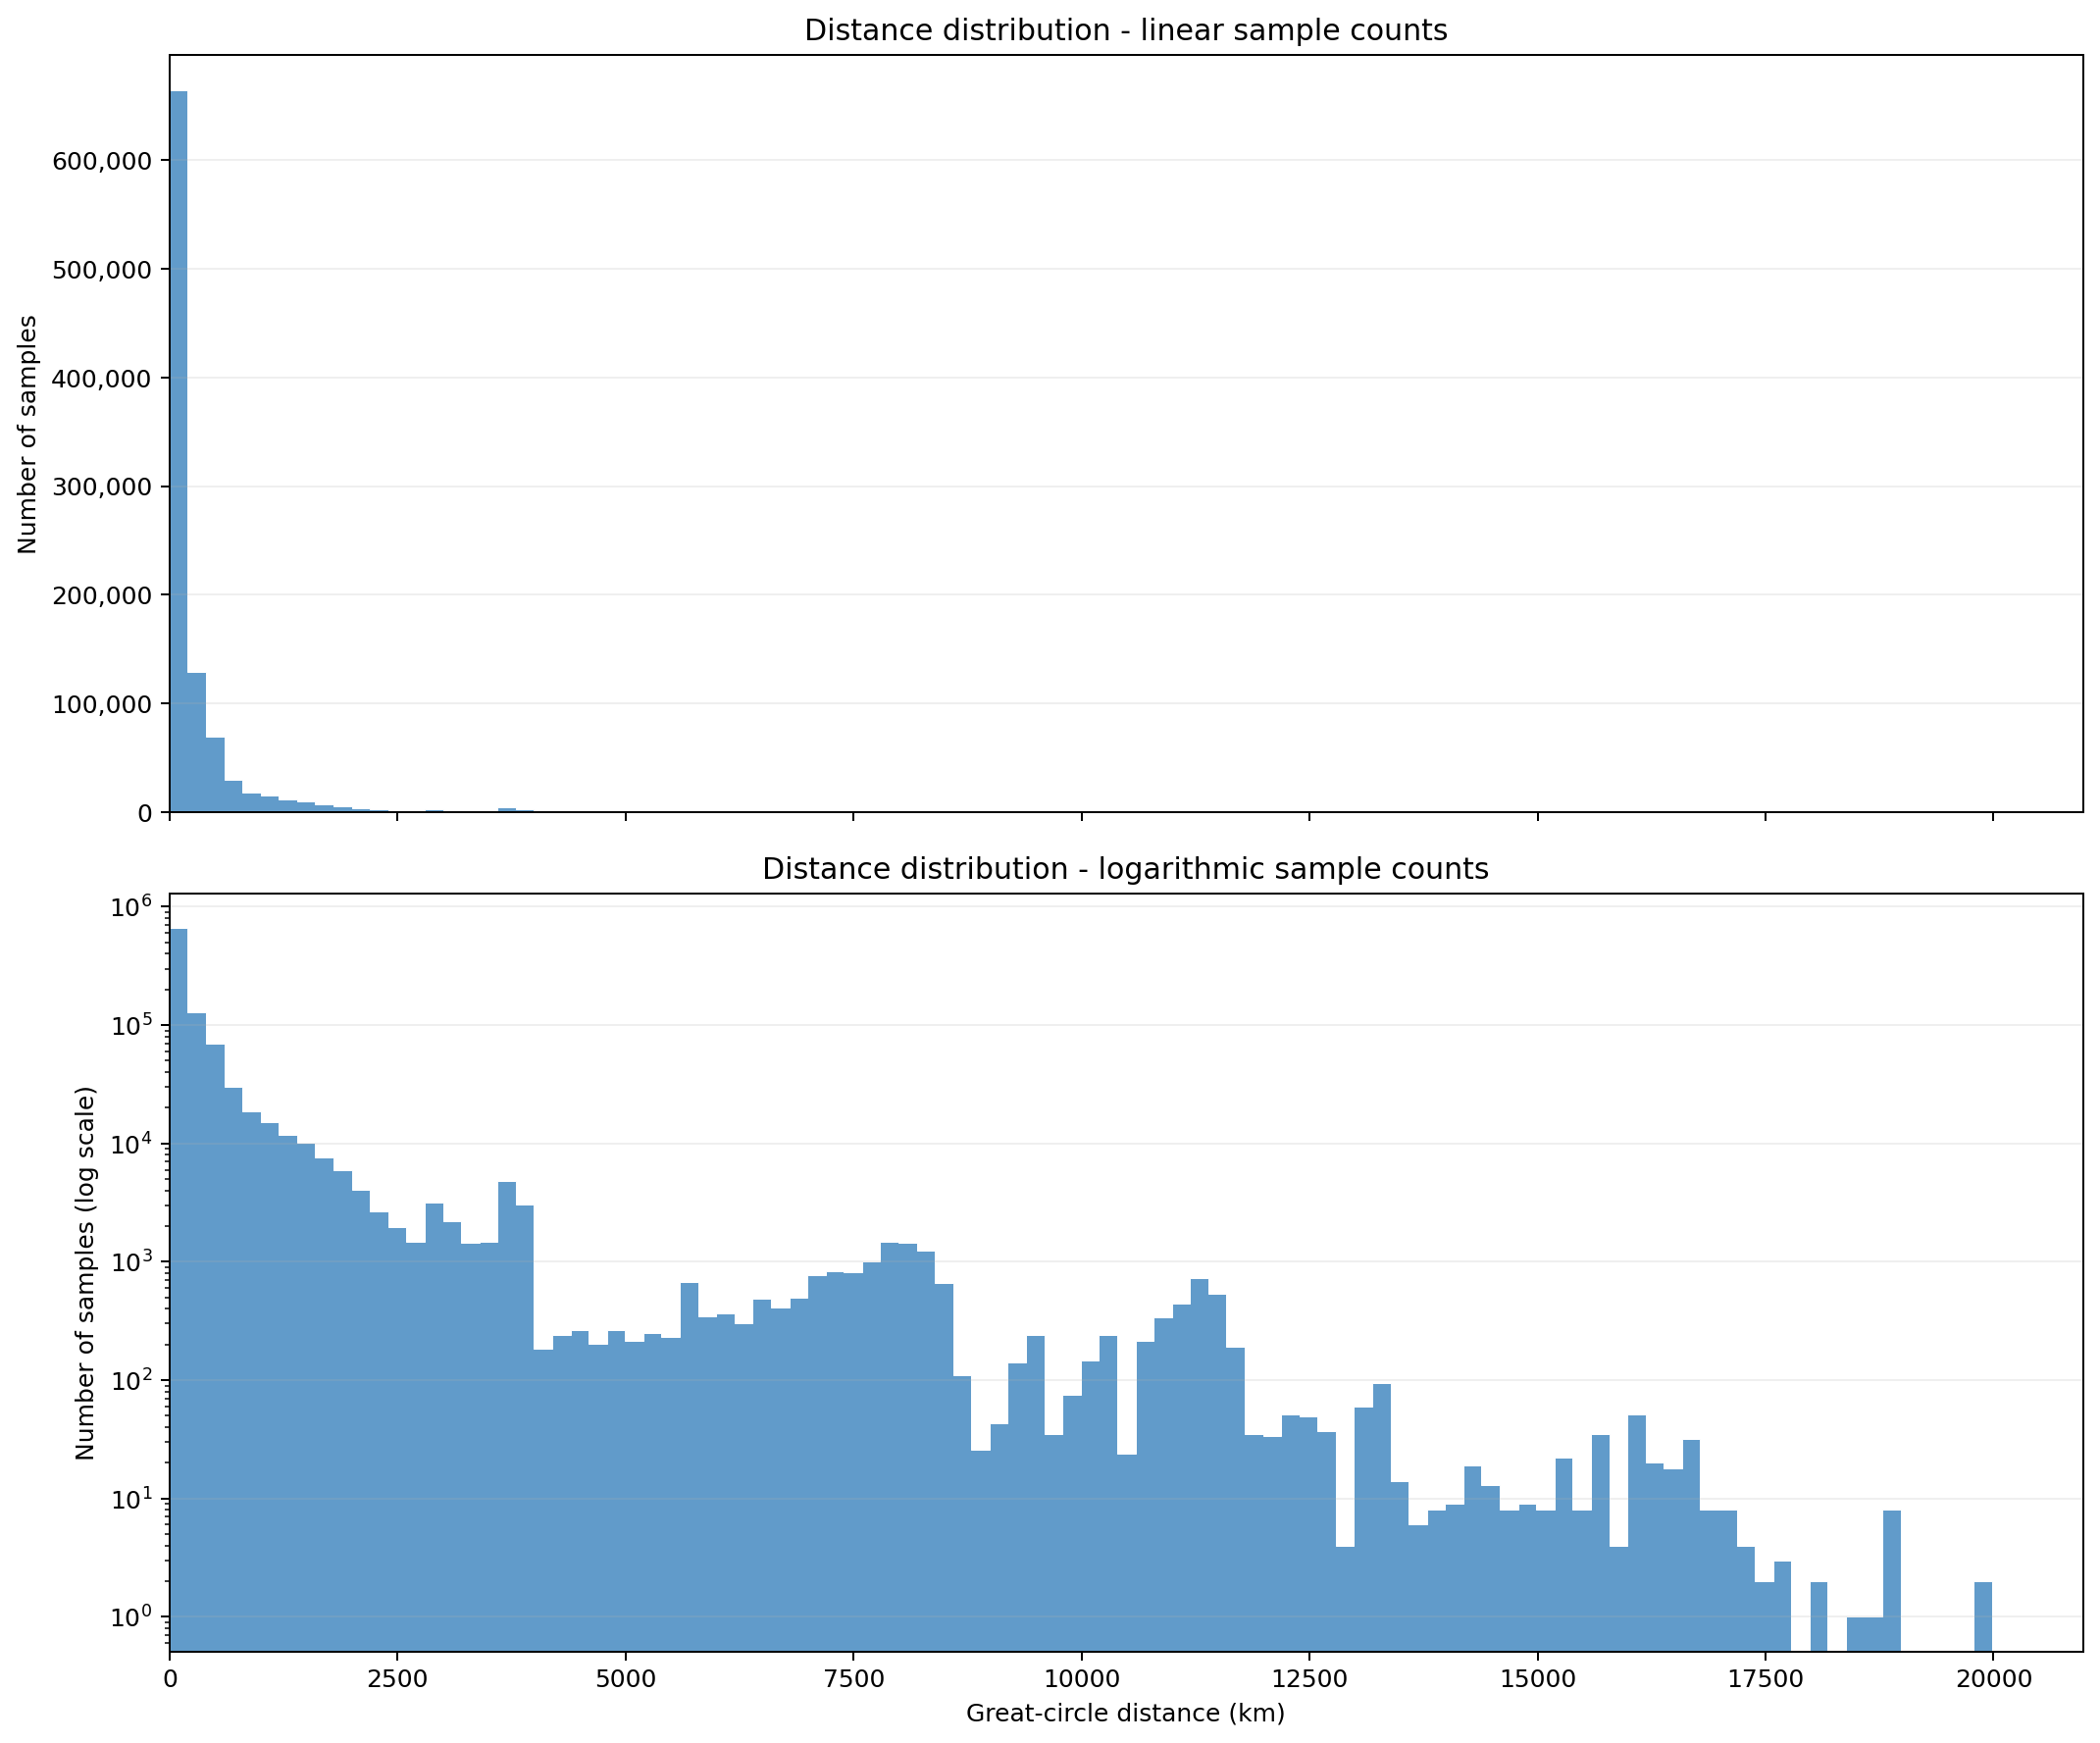

In [ ]:
if not len(linked_distances_km):
    raise ValueError("No linked entity pairs with both coordinates were found.")

q1_km, median_km, q3_km = np.percentile(linked_distances_km, [25, 50, 75])
mean_km = linked_distances_km.mean()
distance_summary = pd.DataFrame({
    "statistic": [
        "Minimum", "First quartile (Q1, 25%)", "Median (Q2, 50%)",
        "Third quartile (Q3, 75%)", "Maximum", "Average (mean)",
        "Standard deviation (population)",
    ],
    "distance_km": [
        linked_distances_km.min(), q1_km, median_km, q3_km,
        linked_distances_km.max(), mean_km, linked_distances_km.std(ddof=0),
    ],
})
print(f"Geographic distances for {len(linked_distances_km):,} unique linked entity pairs")
display(distance_summary.round(2))

fig, (linear_ax, log_ax) = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
distance_hist_counts, distance_hist_edges = np.histogram(linked_distances_km, bins=100)
for ax in (linear_ax, log_ax):
    ax.stairs(
        distance_hist_counts, distance_hist_edges, fill=True,
        color="#619bca", edgecolor="white", linewidth=0.4,
    )
    ax.set_xscale("linear")
    ax.set_xlim(left=0)
    ax.grid(axis="y", alpha=0.2)

linear_ax.set_title("Distance distribution - linear sample counts")
linear_ax.set_ylabel("Number of samples")
linear_ax.set_ylim(bottom=0)
linear_ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, position: f"{value:,.0f}"))
log_ax.set_title("Distance distribution - logarithmic sample counts")
log_ax.set_yscale("log")
log_ax.set_ylabel("Number of samples (log scale)")
log_ax.set_xlabel("Great-circle distance (km)")
fig.tight_layout()

# Save and display the two static histograms without metric annotations.
os.makedirs("./figures", exist_ok=True)
distance_distribution_path = "./figures/linked_entity_distance_distribution.png"
fig.savefig(distance_distribution_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=distance_distribution_path))


## Static location heatmap - logarithmic entity counts per 1-degree cell

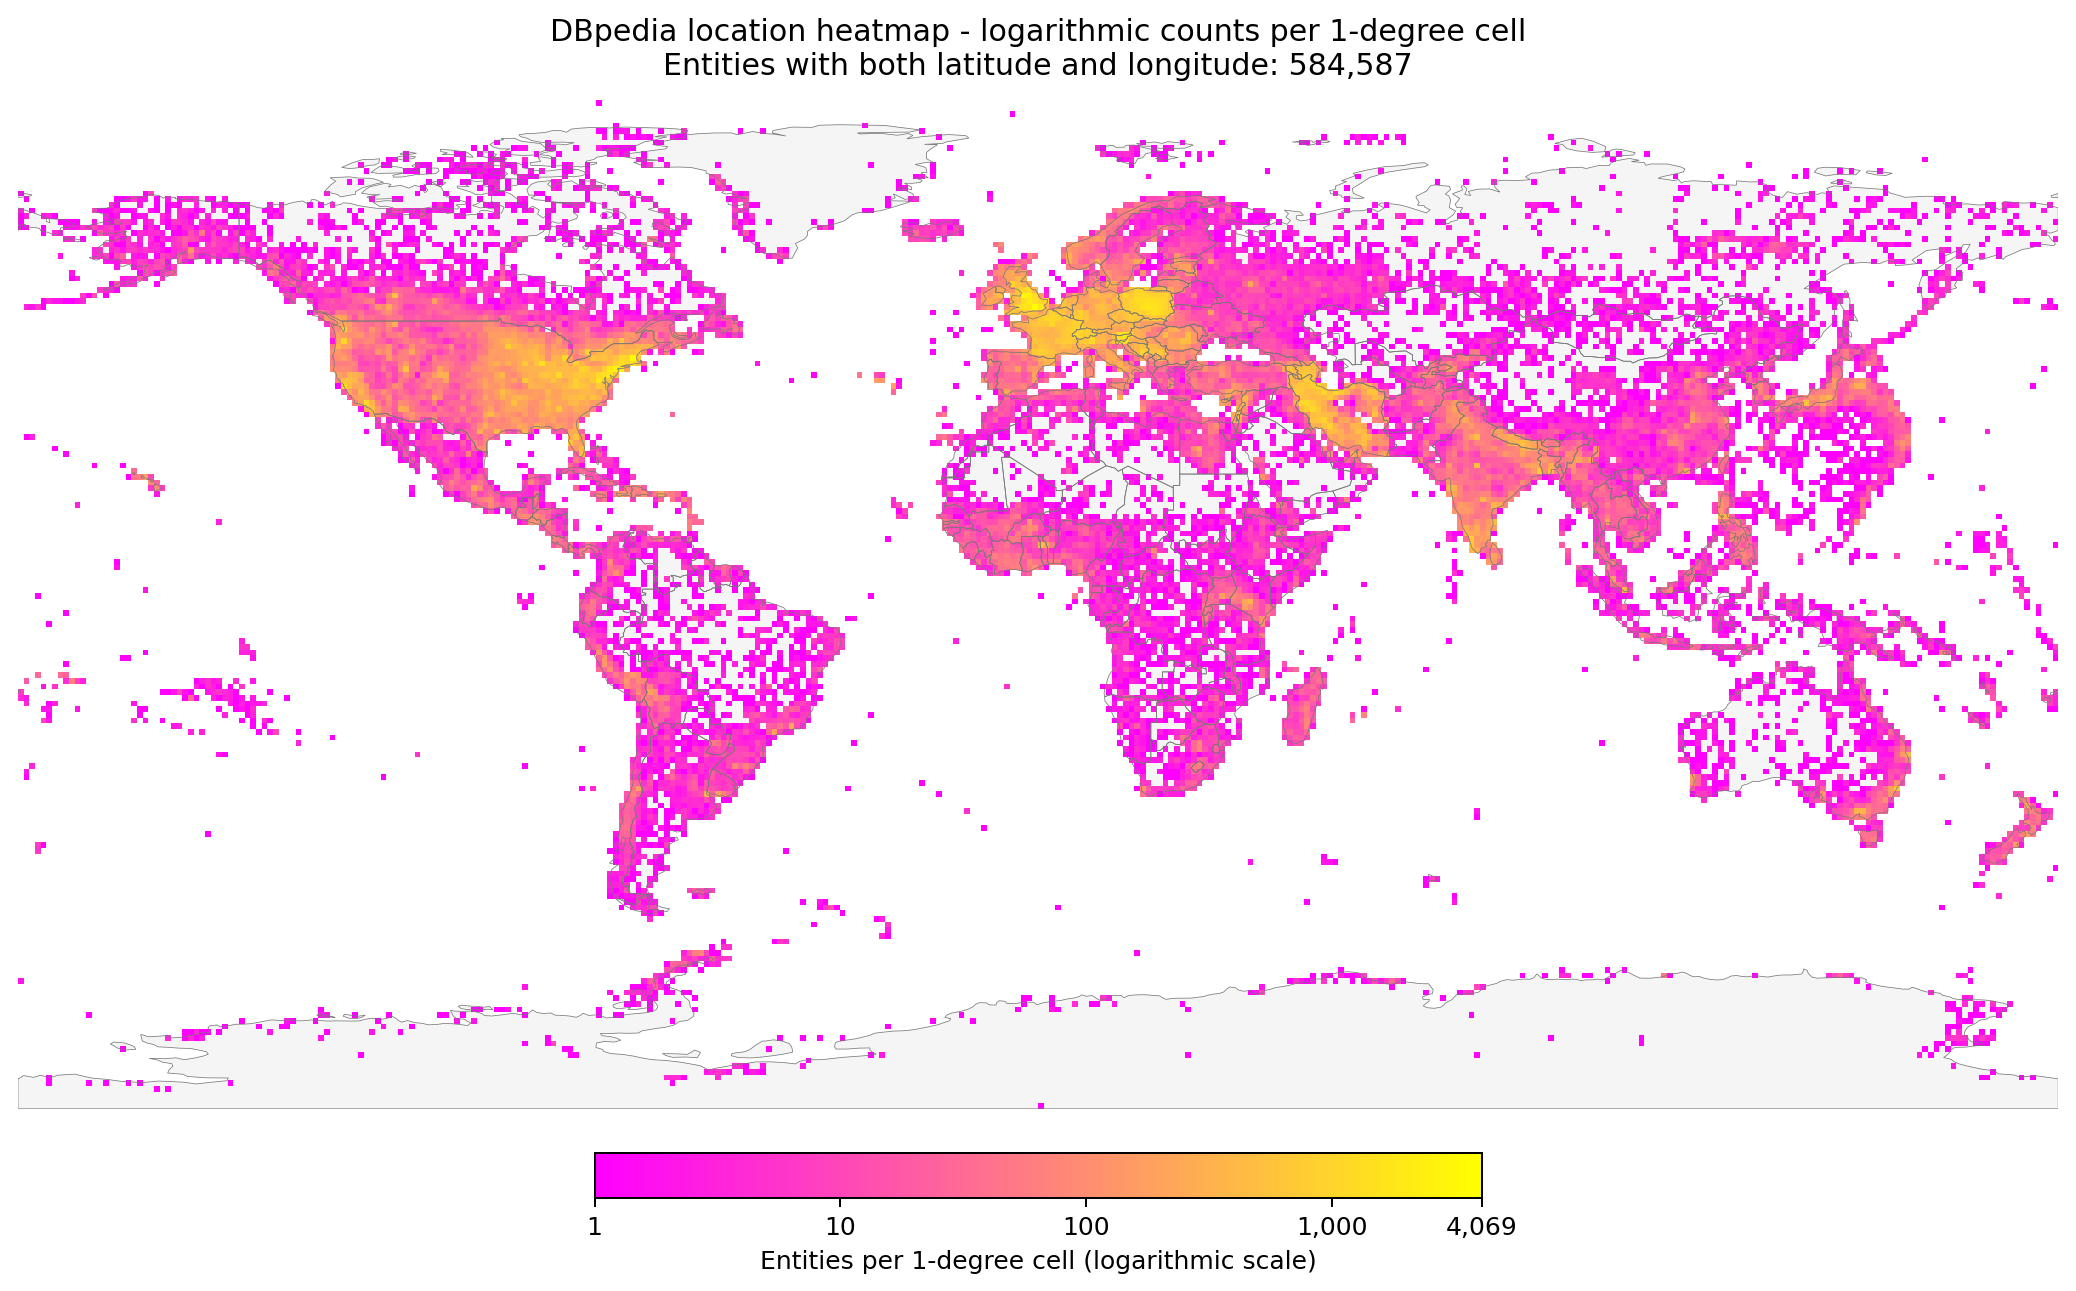

In [14]:
# Use only entities with both coordinates, as in the attribute and type counts.
map_coordinates = coordinates.dropna(subset=["latitude", "longitude"])
if map_coordinates.empty:
    raise ValueError("No entities have both latitude and longitude.")

world = gpd.read_file("./data/world_countries.geojson").to_crs("EPSG:4326")

# Count entities in 1-degree cells; omit empty cells for logarithmic colors.
grid_size = 1
latitude_edges = np.arange(-90, 90 + grid_size, grid_size)
longitude_edges = np.arange(-180, 180 + grid_size, grid_size)
grid_counts, _, _ = np.histogram2d(
    map_coordinates["latitude"], map_coordinates["longitude"],
    bins=[latitude_edges, longitude_edges],
)
latitude_bins, longitude_bins = np.nonzero(grid_counts)
cell_counts = grid_counts[latitude_bins, longitude_bins].astype(int)
if not len(cell_counts):
    raise ValueError("No coordinate pairs fall within the world map bounds.")
heatmap_grid = gpd.GeoDataFrame(
    {"entity_count": cell_counts},
    geometry=[
        box(longitude_edges[lon_bin], latitude_edges[lat_bin],
            longitude_edges[lon_bin + 1], latitude_edges[lat_bin + 1])
        for lat_bin, lon_bin in zip(latitude_bins, longitude_bins)
    ],
    crs="EPSG:4326",
)

max_count = int(cell_counts.max())
norm = LogNorm(vmin=1, vmax=max(max_count, 2))
fig, ax = plt.subplots(figsize=(16, 8))
gplt.polyplot(world, ax=ax, facecolor="#f5f5f5", edgecolor="none", zorder=0)
gplt.choropleth(
    heatmap_grid, hue="entity_count", cmap="spring", norm=norm,
    ax=ax, edgecolor="none", linewidth=0, zorder=1,
)
gplt.polyplot(world, ax=ax, facecolor="none", edgecolor="#777777", linewidth=0.3, zorder=2)
ax.set_xlim(-180, 180)
ax.set_ylim(-90, 90)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title(
    "DBpedia location heatmap - logarithmic counts per 1-degree cell\n"
    f"Entities with both latitude and longitude: {len(map_coordinates):,}"
)
legend_counts = 10 ** np.arange(int(np.floor(np.log10(max_count))) + 1)
if legend_counts[-1] != max_count:
    legend_counts = np.append(legend_counts, max_count)
colorbar = fig.colorbar(
    ScalarMappable(norm=norm, cmap="spring"), ax=ax,
    orientation="horizontal", fraction=0.04, pad=0.04,
)
colorbar.set_ticks(legend_counts, labels=[f"{count:,}" for count in legend_counts])
colorbar.minorticks_off()
colorbar.set_label("Entities per 1-degree cell (logarithmic scale)")

# Render a static image regardless of the notebook's active plotting backend.
os.makedirs("./figures", exist_ok=True)
heatmap_path = "./figures/dbpedia_location_heatmap.png"
fig.savefig(heatmap_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=heatmap_path))
